# UTS Pembelajaran Mesin

## 1. Import library

In [1]:
#202431144_Armando_Sianipar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split as tts
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Membaca data mentah

In [2]:
#202431144_Armando_Sianipar
raw = pd.read_csv("Filedata Jumlah Penumpang Angkutan Umum yang Terlayani per Hari Tahun 2023.csv", encoding="utf-8-sig")
raw.columns = ["periode", "tanggal", "moda", "jumlah"]
raw

,periode,tanggal,moda,jumlah
0,202301,2023-01-01,bus sekolah,0
1,202301,2023-01-02,bus sekolah,33547
2,202301,2023-01-03,bus sekolah,38123
3,202301,2023-01-04,bus sekolah,40740
4,202301,2023-01-05,bus sekolah,42587
...,...,...,...,...
2550,202312,2023-12-27,transjakarta,1012112
2551,202312,2023-12-28,transjakarta,1010097
2552,202312,2023-12-29,transjakarta,974703
2553,202312,2023-12-30,transjakarta,748326


In [3]:
#202431144_Armando_Sianipar
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2555 entries, 0 to 2554
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   periode  2555 non-null   int64 
 1   tanggal  2555 non-null   object
 2   moda     2555 non-null   object
 3   jumlah   2555 non-null   object
dtypes: int64(1), object(3)
memory usage: 80.0+ KB


In [4]:
#202431144_Armando_Sianipar
print("Baris kosong total      :", (raw.tanggal.str.strip() == "").sum())
print("Variasi nama moda       :", raw.moda.nunique())
print("Pola tanggal            :", raw.tanggal.str.replace(r"\d", "9", regex=True).value_counts().to_dict())
print("Pola angka jumlah       :", raw.jumlah.str.strip().str.replace(r"\d+", "9", regex=True).value_counts().to_dict())

Baris kosong total      : 62
Variasi nama moda       : 21
Pola tanggal            : {'9999-99-99': 1639, '9999 99 99': 644, ' 9999 99 99 ': 210, ' ': 62}
Pola angka jumlah       : {'9': 2168, '9,9': 166, '9.9': 138, '': 83}


## 3. Data cleaning

In [5]:
#202431144_Armando_Sianipar
df = raw[raw.tanggal.str.strip() != ""].copy()
df["moda"] = df.moda.str.strip().str.lower()
df["tanggal"] = pd.to_datetime(df.tanggal.str.strip().str.replace(" ", "-"))
df["jumlah"] = pd.to_numeric(df.jumlah.str.strip().str.replace(",", "").str.replace(".", "", regex=False).replace("", np.nan))
print(df.shape)
df.head()

(2493, 4)


,periode,tanggal,moda,jumlah
0,202301,2023-01-01,bus sekolah,0.0
1,202301,2023-01-02,bus sekolah,33547.0
2,202301,2023-01-03,bus sekolah,38123.0
3,202301,2023-01-04,bus sekolah,40740.0
4,202301,2023-01-05,bus sekolah,42587.0


## 4. EDA — missing value, statistik, outlier

In [6]:
#202431144_Armando_Sianipar
print("Missing value per kolom :")
print(df.isna().sum())
print("Duplikat (tanggal, moda):", df.duplicated(["tanggal", "moda"]).sum())

Missing value per kolom :
periode     0
tanggal     0
moda        0
jumlah     21
dtype: int64
Duplikat (tanggal, moda): 0


In [7]:
#202431144_Armando_Sianipar
w = df.pivot(index="tanggal", columns="moda", values="jumlah")
print("Hari tanpa data per moda:")
print(w.isna().sum())
print("Tanggal KRL kosong:", w.index[w.krl.isna()].strftime("%d-%b").tolist())
print("Tanggal KRL = 0   :", w.index[w.krl == 0].strftime("%d-%b").tolist())

Hari tanpa data per moda:
moda
bus sekolah               0
kapal                     1
kci commuter bandara    100
krl                      41
lrt                       0
mrt                       0
railink                 306
transjakarta              0
dtype: int64
Tanggal KRL kosong: ['01-Mar', '02-Mar', '03-Mar', '04-Mar', '05-Mar', '06-Mar', '07-Mar', '08-Mar', '09-Mar', '10-Mar', '11-Mar', '12-Mar', '13-Mar', '14-Mar', '15-Mar', '16-Mar', '17-Mar', '18-Mar', '19-Mar', '20-Mar', '21-Mar', '22-Mar', '23-Mar', '24-Mar', '25-Mar', '26-Mar', '27-Mar', '28-Mar', '29-Mar', '30-Mar', '31-Mar', '21-Jul', '22-Jul', '23-Jul', '27-Jul', '28-Jul', '29-Jul', '30-Jul', '31-Jul', '30-Aug', '31-Aug']
Tanggal KRL = 0   : ['30-Sep', '26-Oct', '27-Oct', '28-Oct', '29-Oct', '30-Oct', '31-Oct', '29-Nov', '30-Nov']


In [8]:
#202431144_Armando_Sianipar
w[["krl", "mrt", "lrt", "transjakarta"]].describe().round(0)

moda,krl,mrt,lrt,transjakarta
count,324.0,365.0,365.0,365.0
mean,748927.0,91381.0,2788.0,632706.0
std,174300.0,24973.0,442.0,324799.0
min,0.0,26022.0,1533.0,24204.0
25%,660680.0,67729.0,2529.0,391089.0
50%,805652.0,100269.0,2819.0,538248.0
75%,869073.0,110811.0,3059.0,989925.0
max,929964.0,163162.0,6123.0,1174098.0


In [9]:
#202431144_Armando_Sianipar
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    return lo, hi, s[(s < lo) | (s > hi)]

for c in ["krl", "mrt", "lrt", "transjakarta", "kapal"]:
    lo, hi, out = iqr_outliers(w[c].dropna())
    print(c, "batas =", round(lo), "-", round(hi), "| outlier =", len(out))

krl batas = 348090 - 1181663 | outlier = 10
mrt batas = 3106 - 175434 | outlier = 0
lrt batas = 1734 - 3854 | outlier = 8
transjakarta batas = -507165 - 1888179 | outlier = 0
kapal batas = -6000 - 11116 | outlier = 35


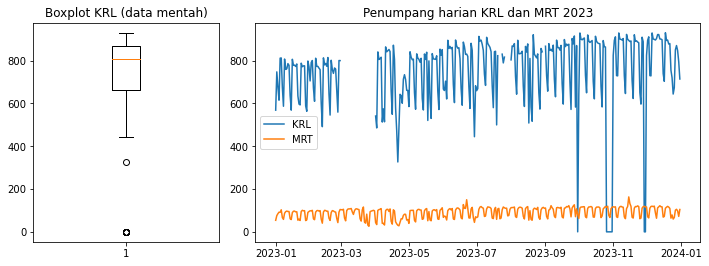

In [10]:
#202431144_Armando_Sianipar
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1, 2.4]})
ax[0].boxplot((w.krl/1000).dropna()); ax[0].set_title("Boxplot KRL (data mentah)")
ax[1].plot(w.index, w.krl/1000, label="KRL"); ax[1].plot(w.index, w.mrt/1000, label="MRT")
ax[1].set_title("Penumpang harian KRL dan MRT 2023"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Sampel perhitungan manual: 6–26 Juli 2023 (21 data)

In [11]:
#202431144_Armando_Sianipar
s = w.loc["2023-07-06":"2023-07-26", ["mrt", "krl"]].copy()
s["x"] = (s.mrt / 1000).round(0)       # ribu penumpang
s["y"] = (s.krl / 1000).round(0)
s = s[["x", "y"]]
print("Jumlah data awal:", len(s))
s

Jumlah data awal: 21


moda,x,y
tanggal,,
2023-07-06,113.0,876.0
2023-07-07,111.0,848.0
2023-07-08,72.0,737.0
2023-07-09,74.0,684.0
2023-07-10,107.0,909.0
2023-07-11,117.0,880.0
2023-07-12,115.0,871.0
2023-07-13,114.0,862.0
2023-07-14,109.0,842.0


In [12]:
#202431144_Armando_Sianipar
kosong = s[s.y.isna()]
print("Dihapus:", kosong.index.strftime("%d-%b").tolist())
v = s.dropna()
print("Sisa data:", len(v))

Dihapus: ['21-Jul', '22-Jul', '23-Jul']
Sisa data: 18


In [13]:
#202431144_Armando_Sianipar
def tukey(vals):
    a = sorted(vals); n = len(a); h = n // 2
    q1 = np.median(a[:h]); q3 = np.median(a[h + n % 2:]); iqr = q3 - q1
    return q1, q3, iqr, q1 - 1.5*iqr, q3 + 1.5*iqr

q1, q3, iqr, lo, hi = tukey(v.y.tolist())
print("Y: Q1 =", q1, "Q3 =", q3, "IQR =", iqr, "batas bawah =", lo, "batas atas =", hi)
print(v[(v.y < lo) | (v.y > hi)])
q1x, q3x, iqrx, lox, hix = tukey(v.x.tolist())
print("X: Q1 =", q1x, "Q3 =", q3x, "IQR =", iqrx, "batas =", lox, "-", hix, "| outlier X =", ((v.x < lox) | (v.x > hix)).sum())

Y: Q1 = 737.0 Q3 = 862.0 IQR = 125.0 batas bawah = 549.5 batas atas = 1049.5
moda           x      y
tanggal                
2023-07-19  58.0  499.0
X: Q1 = 74.0 Q3 = 114.0 IQR = 40.0 batas = 14.0 - 174.0 | outlier X = 0


In [14]:
#202431144_Armando_Sianipar
print("Mean   X =", round(v.x.mean(), 2), "| Y =", round(v.y.mean(), 2))
print("Median X =", v.x.median(), "| Y =", v.y.median())
print("Std    X =", round(v.x.std(), 2), "| Y =", round(v.y.std(), 2))

Mean   X = 98.44 | Y = 789.72
Median X = 108.0 | Y = 835.5
Std    X = 21.34 | Y = 111.25


In [15]:
#202431144_Armando_Sianipar
db = v[(v.y >= lo) & (v.y <= hi)]
print("Data akhir:", len(db))
db.corr()

Data akhir: 17


moda,x,y
moda,,
x,1.000000,0.897671
y,0.897671,1.000000


## 6. Regresi Linier — rumus manual

In [16]:
#202431144_Armando_Sianipar
x = db.x.values; y = db.y.values; n = len(x)
tabel = pd.DataFrame({"X": x, "Y": y, "X2": x**2, "Y2": y**2, "XY": x*y})
tabel.loc["Total"] = tabel.sum()
tabel

,X,Y,X2,Y2,XY
0,113.0,876.0,12769.0,767376.0,98988.0
1,111.0,848.0,12321.0,719104.0,94128.0
2,72.0,737.0,5184.0,543169.0,53064.0
3,74.0,684.0,5476.0,467856.0,50616.0
4,107.0,909.0,11449.0,826281.0,97263.0
5,117.0,880.0,13689.0,774400.0,102960.0
6,115.0,871.0,13225.0,758641.0,100165.0
7,114.0,862.0,12996.0,743044.0,98268.0
8,109.0,842.0,11881.0,708964.0,91778.0
9,64.0,684.0,4096.0,467856.0,43776.0


In [17]:
#202431144_Armando_Sianipar
Sx, Sy, Sxx, Syy, Sxy = x.sum(), y.sum(), (x**2).sum(), (y**2).sum(), (x*y).sum()
print("n =", n, "| SX =", Sx, "| SY =", Sy, "| SXX =", Sxx, "| SYY =", Syy, "| SXY =", Sxy)
print("Rata-rata X =", round(Sx/n, 2), "| Rata-rata Y =", round(Sy/n, 2))

pembilang = n*Sxy - Sx*Sy
penyebut = n*Sxx - Sx**2
b = pembilang / penyebut
a = (Sy - b*Sx) / n
print("Pembilang =", pembilang, "| Penyebut =", penyebut)
print("b (slope)     =", round(b, 4))
print("a (intercept) =", round(a, 4))
print("Persamaan : Y =", round(a, 2), "+", round(b, 4), "X")

n = 17 | SX = 1714.0 | SY = 13716.0 | SXX = 178818.0 | SYY = 11187314.0 | SXY = 1407088.0
Rata-rata X = 100.82 | Rata-rata Y = 806.82
Pembilang = 411272.0 | Penyebut = 102110.0
b (slope)     = 4.0277
a (intercept) = 400.7331
Persamaan : Y = 400.73 + 4.0277 X


In [18]:
#202431144_Armando_Sianipar
yhat = a + b*x
e = y - yhat
SSE = (e**2).sum(); SST = ((y - y.mean())**2).sum()
r = pembilang / np.sqrt(penyebut * (n*Syy - Sy**2))
print("SSE  =", round(SSE, 1), "| SST =", round(SST, 1))
print("R2   =", round(1 - SSE/SST, 4))
print("r    =", round(r, 4))
print("MAE  =", round(np.abs(e).mean(), 2))
print("RMSE =", round(np.sqrt(SSE/n), 2))
print("MAPE =", round((np.abs(e)/y).mean()*100, 2), "%")
pd.DataFrame({"X": x, "Y": y, "Y_hat": yhat.round(2), "e": e.round(2)})

SSE  = 23481.6 | SST = 120922.5
R2   = 0.8058
r    = 0.8977
MAE  = 26.9
RMSE = 37.17
MAPE = 3.53 %


,X,Y,Y_hat,e
0,113.0,876.0,855.87,20.13
1,111.0,848.0,847.81,0.19
2,72.0,737.0,690.73,46.27
3,74.0,684.0,698.79,-14.79
4,107.0,909.0,831.70,77.30
5,117.0,880.0,871.98,8.02
6,115.0,871.0,863.92,7.08
7,114.0,862.0,859.89,2.11
8,109.0,842.0,839.76,2.24
9,64.0,684.0,658.51,25.49


## 7. Verifikasi dengan scikit-learn

In [19]:
#202431144_Armando_Sianipar
x_train = db["x"].values[:, np.newaxis]
y_train = db["y"].values
lm = LinearRegression()
lm.fit(x_train, y_train)
print("Coefficient :", lm.coef_)
print("Intercept :", lm.intercept_)

Coefficient : [4.0277348]
Intercept : 400.73309176378416


In [20]:
#202431144_Armando_Sianipar
x_test = kosong[["x"]].values
p = lm.predict(x_test)
pd.DataFrame({"X (MRT)": kosong.x.values, "Prediksi KRL": p.round(2)}, index=kosong.index.strftime("%d-%b"))

,X (MRT),Prediksi KRL
tanggal,,
21-Jul,110.0,843.78
22-Jul,61.0,646.42
23-Jul,65.0,662.54


In [21]:
#202431144_Armando_Sianipar
lm2 = LinearRegression().fit(v[["x"]].values, v.y.values)
print("Tanpa outlier :", round(lm.intercept_, 2), "+", round(lm.coef_[0], 4), "X | R2 =", round(lm.score(x_train, y_train), 3))
print("Dengan outlier:", round(lm2.intercept_, 2), "+", round(lm2.coef_[0], 4), "X | R2 =", round(lm2.score(v[["x"]].values, v.y.values), 3))

Tanpa outlier : 400.73 + 4.0277 X | R2 = 0.806
Dengan outlier: 323.58 + 4.7351 X | R2 = 0.825


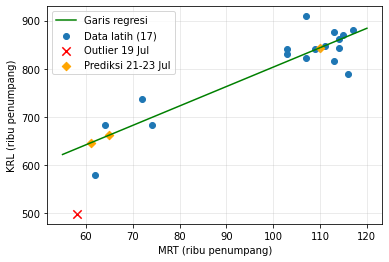

In [22]:
#202431144_Armando_Sianipar
plt.scatter(db["x"], db["y"], label="Data latih (17)")
plt.scatter(v[v.y < lo]["x"], v[v.y < lo]["y"], color="red", marker="x", s=70, label="Outlier 19 Jul")
xx = np.linspace(55, 120, 50)
plt.plot(xx, lm.predict(xx[:, np.newaxis]), color="green", label="Garis regresi")
plt.scatter(kosong["x"], p, color="orange", marker="D", label="Prediksi 21-23 Jul")
plt.xlabel("MRT (ribu penumpang)"); plt.ylabel("KRL (ribu penumpang)"); plt.legend(); plt.grid(alpha=.3)
plt.show()

## 8. Model pada seluruh dataset (train/test split)

In [23]:
#202431144_Armando_Sianipar
d = w[["mrt", "krl"]].copy()
d.loc[d.krl == 0, "krl"] = np.nan
print("Baris awal:", len(d), "| baris dengan missing:", d.isna().any(axis=1).sum())
d = d.dropna()
d = d / 1000
d["rasio"] = d.krl / d.mrt
lo_r, hi_r, out_r = iqr_outliers(d.rasio)
print("Batas rasio KRL/MRT:", round(lo_r, 2), "-", round(hi_r, 2), "| outlier:", len(out_r))
d_bersih = d[(d.rasio >= lo_r) & (d.rasio <= hi_r)]
print("Data bersih:", len(d_bersih))

Baris awal: 365 | baris dengan missing: 50
Batas rasio KRL/MRT: 4.44 - 13.09 | outlier: 10
Data bersih: 305


In [24]:
#202431144_Armando_Sianipar
X = d_bersih[["mrt"]]
Y = d_bersih["krl"]
x_train, x_test, y_train, y_test = tts(X, Y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
print("Data latih:", len(x_train), "| data uji:", len(x_test))
print("Koefisien :", model.coef_)
print("Intercept :", model.intercept_)

Data latih: 244 | data uji: 61
Koefisien : [4.35409678]
Intercept : 369.32732686121125


In [25]:
#202431144_Armando_Sianipar
print("R2 score :", r2_score(y_test, y_pred))
print("MAE      :", mean_absolute_error(y_test, y_pred))
print("MSE      :", mean_squared_error(y_test, y_pred))
print("RMSE     :", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 score : 0.8611246834702829
MAE      : 32.10777968121532
MSE      : 2069.6768207380956
RMSE     : 45.49370089076174


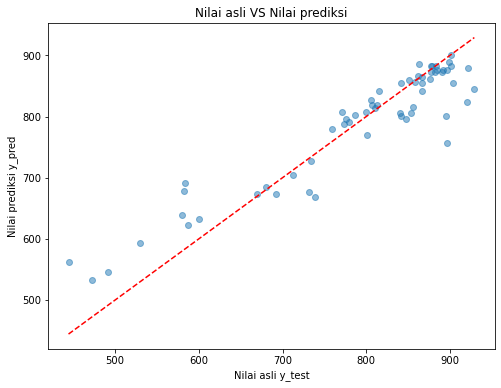

In [26]:
#202431144_Armando_Sianipar
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Nilai asli y_test")
plt.ylabel("Nilai prediksi y_pred")
plt.title("Nilai asli VS Nilai prediksi")
mn, mx = y_test.min(), y_test.max()
plt.plot([mn, mx], [mn, mx], "r--")
plt.show()

In [27]:
#202431144_Armando_Sianipar
kf = w.loc[w.krl.isna() & w.mrt.notna() & (w.index.month != 3)]
est = pd.DataFrame({"mrt": (kf.mrt/1000)})
est["Estimasi KRL (ribu)"] = model.predict(est[["mrt"]]).round(1)
est["mrt"] = est.mrt.round(1)
est.rename(columns={"mrt": "MRT (ribu)"})

,MRT (ribu),Estimasi KRL (ribu)
tanggal,,
2023-07-21,109.7,847.0
2023-07-22,61.0,635.0
2023-07-23,64.5,650.4
2023-07-27,109.7,847.1
2023-07-28,110.7,851.5
2023-07-29,74.6,694.1
2023-07-30,76.6,702.7
2023-07-31,105.5,828.6
2023-08-30,114.4,867.3
